# Separating cell-carried from surface-carried colonization history (v1.0)

This notebook reruns a reduced version of every analysis in the package: unit tests,
the calibrated factorial comparison, the mechanism-recovery study and the empirical
re-analysis of Lee *et al.* (2018) from the shipped observables. Reduced ensemble
sizes give noisier numbers than the full runs reported in the manuscript; the full
commands are listed in `README.md`.

Run it from the package directory, or in Colab after uploading and unzipping the
package (first cell).

In [1]:
import os, sys, subprocess, zipfile, glob
if not os.path.exists('model.py'):
    z = sorted(glob.glob('/content/*Colonization_History_Model_v1*.zip'))
    if z:
        zipfile.ZipFile(z[-1]).extractall('/content')
        os.chdir(glob.glob('/content/colonization_history_v1*')[0])
print(os.getcwd())
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'])

.


CompletedProcess(args=['/usr/local/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [2]:
!python -m unittest test_model -v 2>&1 | tail -25

test_accounting_and_capacity (test_model.Tests.test_accounting_and_capacity) ... ok
test_cell_only_invariant_to_surface_preparation (test_model.Tests.test_cell_only_invariant_to_surface_preparation) ... ok
test_confounders_equal_null_on_untreated_factor (test_model.Tests.test_confounders_equal_null_on_untreated_factor) ... ok
test_equal_incoming_dose (test_model.Tests.test_equal_incoming_dose) ... ok
test_long_gap_erases_preparations (test_model.Tests.test_long_gap_erases_preparations) ... ok
test_no_arrivals_no_population_without_carryover (test_model.Tests.test_no_arrivals_no_population_without_carryover) ... ok
test_no_division_no_descendants (test_model.Tests.test_no_division_no_descendants) ... ok
test_overrides_cannot_activate_inactive_couplings (test_model.Tests.test_overrides_cannot_activate_inactive_couplings) ... ok
test_passive_invariant_to_history (test_model.Tests.test_passive_invariant_to_history) ... ok
test_per_replicate_parameters_are_independent (test_model.Tests.test

## Calibrated factorial comparison

Uses the shipped calibration (`results/logs/calibration.json`). Writes to `nb_results/`.

In [3]:
import shutil, pathlib
out = pathlib.Path('nb_results'); (out/'logs').mkdir(parents=True, exist_ok=True)
shutil.copy('results/logs/calibration.json', out/'logs'/'calibration.json')
!python run_experiments.py --n 100 --check-n 60 --output nb_results | tail -5

  "bootstrap_resamples": 2000,
  "primary_dt": 0.05,
  "max_cell_accounting_error": 0,
  "elapsed_seconds": 25.201825506999967
}


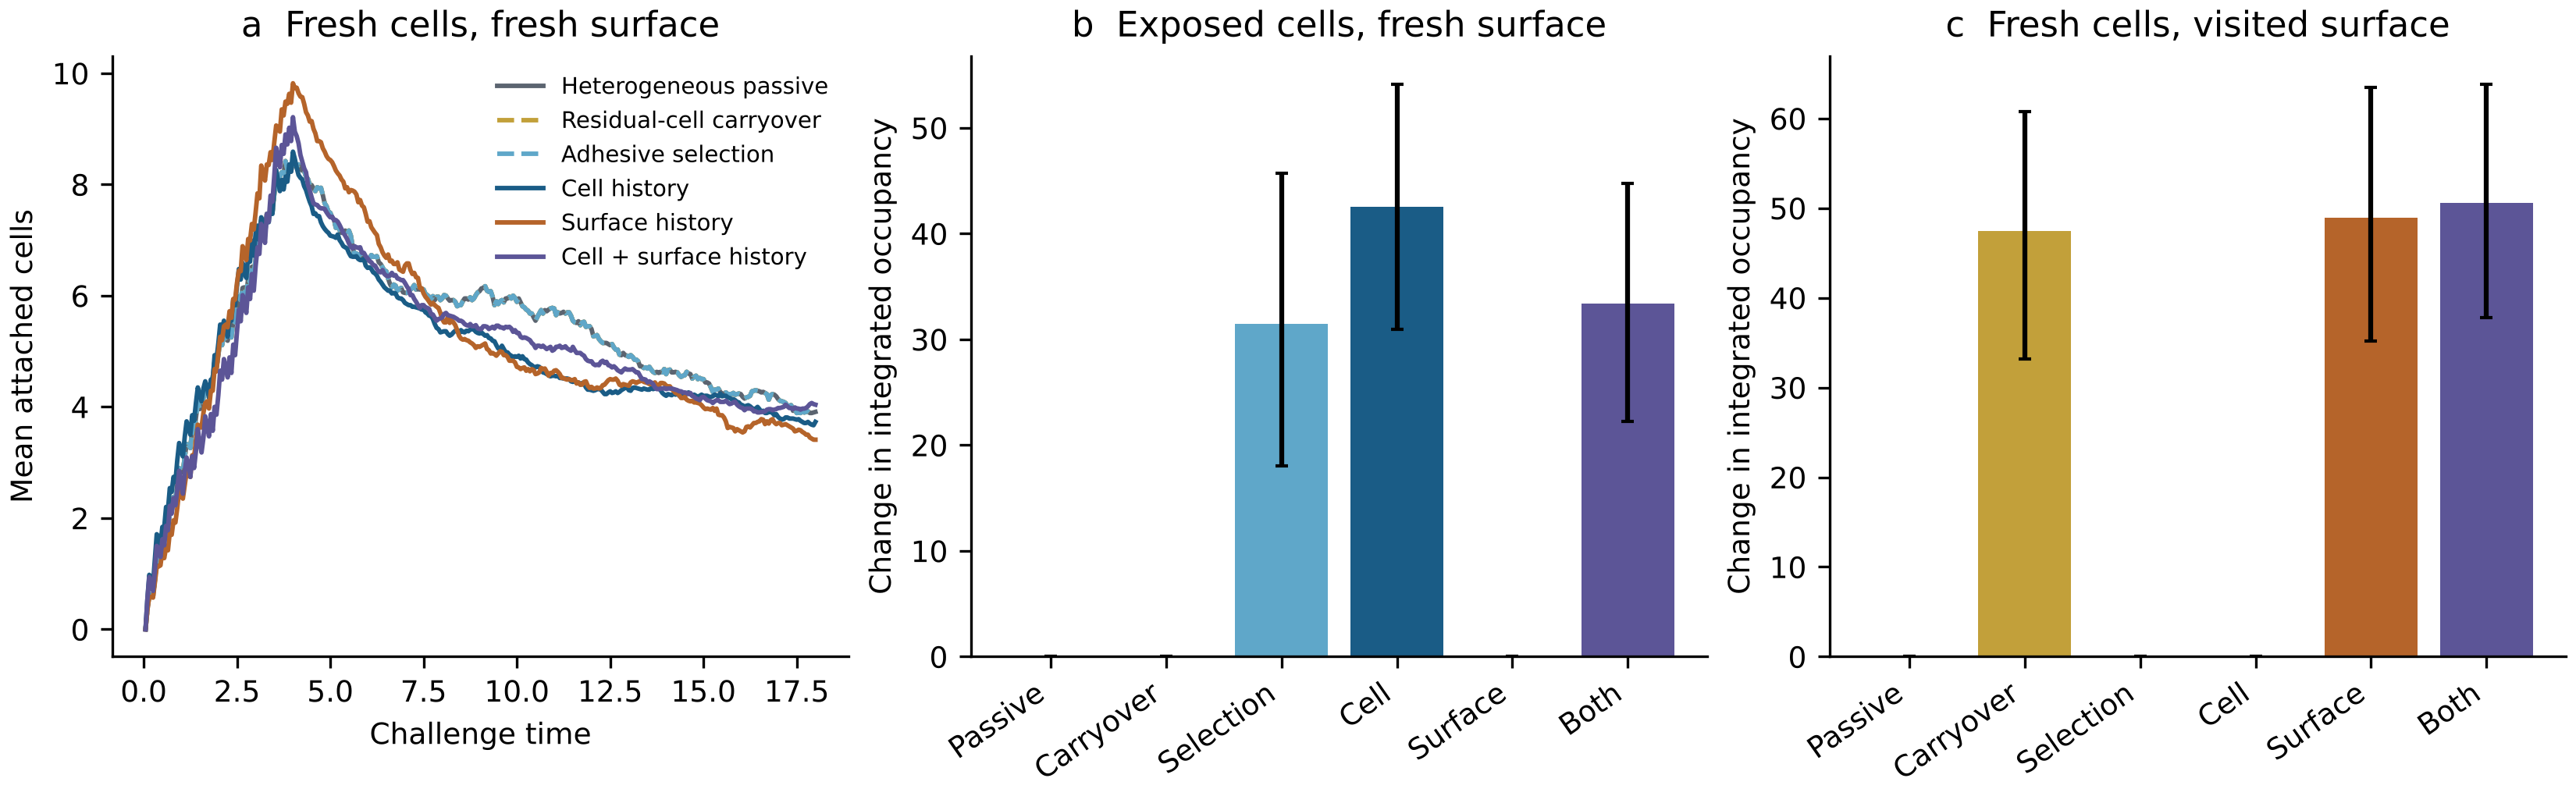

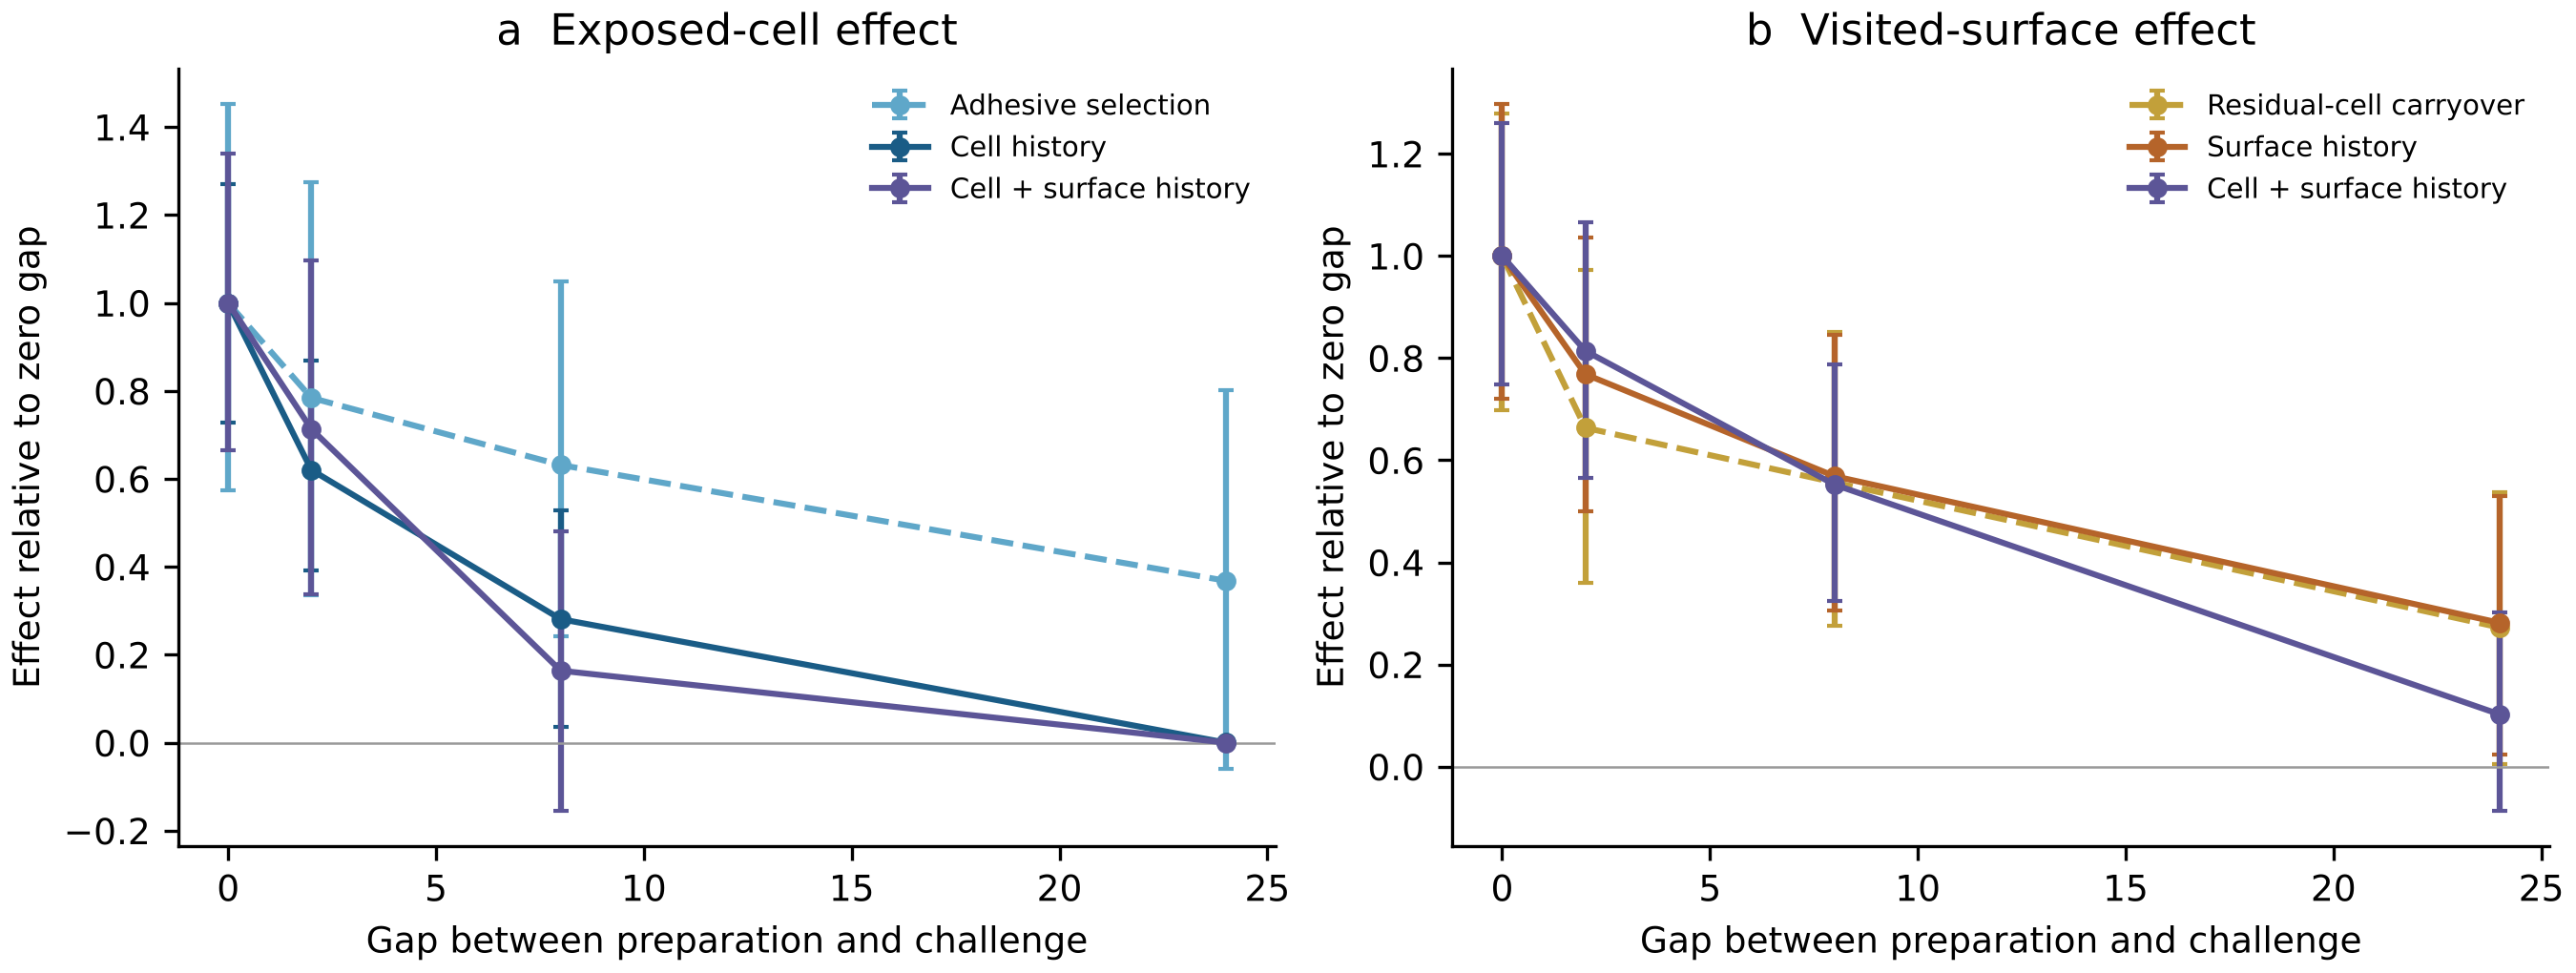

In [4]:
from IPython.display import Image, display
for f in ('fig2_matched_baseline_transfer.png', 'fig3_gap_dependence.png'):
    display(Image(filename=f'nb_results/figures/{f}', width=800))

## Mechanism recovery (reduced: 400 experiments per hypothesis)

Accuracy is lower than in the full study because matching and training sets are
about seven times smaller.

In [5]:
!python recovery.py --n 400 --workers 2 --output nb_results 2>/dev/null | grep -E 'n8\\|gaps0-4-16|baseline'

counts|n2|gaps0-4-16|full 0.252


counts|n2|gaps0-4-16|combined 0.184


counts|n2|gaps0-4-16|exposed 0.272


counts|n4|gaps0-4-16|full 0.301


counts|n4|gaps0-4-16|combined 0.301


counts|n4|gaps0-4-16|exposed 0.214


... (14 outputs left out)

counts|n8|gaps0|baseline 0.146


tracking|n2|gaps0|baseline 0.223


tracking|n4|gaps0|baseline 0.204


tracking|n8|gaps0|baseline 0.175


## Empirical re-analysis from shipped observables

Ten bootstrap resamples here; the manuscript uses 60.

In [6]:
!python empirical/analyze.py 10 nb_results/empirical > /dev/null 2>&1
import json
E = json.load(open('nb_results/empirical/empirical_fits.json'))
for k, v in E['families'].items():
    print(f"{k:28s} k={v['k']:2d} logL={v['loglik']:.1f} AIC={v['aic']:.1f}")
print('adhesiveness shift:', {g: round(x, 3) for g, x in E['families']['selection']['adhesiveness_shift'].items()})
print('LRT selection vs null:', E['lrt_selection_vs_null'])
print('LRT history beyond selection:', E['lrt_history_beyond_selection'])

null                         k= 4 logL=-11109.2 AIC=22226.5
selection_no_acquisition     k= 6 logL=-11109.0 AIC=22230.0
selection                    k= 8 logL=-11103.4 AIC=22222.7
history                      k= 8 logL=-11107.8 AIC=22231.6
selection_and_history        k=12 logL=-11103.3 AIC=22230.6
adhesiveness shift: {'FC1': 0.0, 'FC2': 0.62, 'FC3': 0.445, 'Tr14': 0.101, 'Tr37': -0.144}
LRT selection vs null: {'stat': 11.74943239352433, 'df': 4, 'p': 0.01931514386505566}
LRT history beyond selection: {'stat': 0.09691231113902177, 'df': 4, 'p': 0.9988632451737355}


## Full-record and time-matched fits (point estimates only)

Uses the continuous-tracking observables; bootstrap intervals are in the shipped results.

In [7]:
import sys; sys.path.insert(0, 'empirical')
import analyze_v2 as V
for mode in ('time', 'occupancy'):
    r = V.time_matched(B=0, mode=mode)
    print(mode, 'offset - head start =', round(r['dll_offset_minus_head'], 1),
          'FC2 offset =', round(r['fits']['offset']['offset']['FC2'], 2))

time offset - head start = 42.0 FC2 offset = 0.58


occupancy offset - head start = 60.5 FC2 offset = -0.28
